In [ ]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm, skew, qmc, spearmanr
from scipy.optimize import minimize
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED) 

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# ---------------------------------------------------------------- 
# Figures settings
# ---------------------------------------------------------------- 
SURFACE, INK, INK2, MUTED, GRIDC = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ---------------------------------------------------------------------------
# 1. DATA
# ---------------------------------------------------------------------------
X = np.load('..\Function_6_Data\Week_12_Data/F6_Week_12_inputs.npy')
y = np.load('..\Function_6_Data\Week_12_Data/F6_Week_12_outputs.npy')
n, d = X.shape
N_INITIAL = 20
NEW = n - 1
best = int(np.argmax(y))
xb = X[best]
prev_best = int(np.argmax(y[:NEW]))
xb_prev = X[prev_best]
ym, ys = y.mean(), y.std()
print(f"n = {n} ({N_INITIAL} initial + {n - N_INITIAL} queried); newest x = {np.round(X[NEW], 6)}, y = {y[NEW]:.6f}")
print(f"Best observed: row {best}, x = {np.round(xb, 6)}, y = {y[best]:.6f}; previous best {y[prev_best]:.6f} (row {prev_best}); "
      f"gain {y[best] - y[prev_best]:+.4f}; skew of y = {skew(y):.2f}")
print(f"Step from previous best to newest: {np.round(X[NEW] - xb_prev, 4)} (length {np.linalg.norm(X[NEW] - xb_prev):.3f})")

n = 31 (20 initial + 11 queried); newest x = [0.441509 0.427941 0.45014  0.758566 0.062893], y = -0.363831
Best observed: row 30, x = [0.441509 0.427941 0.45014  0.758566 0.062893], y = -0.363831; previous best -0.404822 (row 27); gain +0.0410; skew of y = -0.26
Step from previous best to newest: [ 0.0073 -0.026   0.0327  0.0279 -0.0629] (length 0.081)


In [3]:
# ---------------------------------------------------------------- 
# Models
# ---------------------------------------------------------------- 
def quad_features(Z):
    Z = np.atleast_2d(Z)
    return np.c_[np.ones(len(Z)), Z, Z ** 2]

def kernel(ard):
    return (ConstantKernel(1.0, (1e-2, 1e2)) * Matern(length_scale=np.ones(d) if ard else 1.0,
                                         length_scale_bounds=(1e-2, 1e1), nu=2.5)
            + WhiteKernel(1e-2, (1e-5, 1e0)))

class GP:
    """GP on standardised y; predictions in raw y units."""
    def __init__(self, ard, k=None):
        self.ard, self.k = ard, k
    def fit(self, Xt, yt):
        self.m, self.s = yt.mean(), yt.std()
        self.g = GaussianProcessRegressor(kernel=self.k or kernel(self.ard), alpha=1e-10,
                                          optimizer=None if self.k else "fmin_l_bfgs_b",
                                          n_restarts_optimizer=0 if self.k else 20,
                                          random_state=SEED).fit(Xt, (yt - self.m) / self.s) #standarized y
        return self
    def predict(self, Z):
        mu, sd = self.g.predict(np.atleast_2d(Z), return_std=True)
        return mu * self.s + self.m, sd * self.s
    def refit_fixed(self):
        return GP(self.ard, self.g.kernel_)

class Hybrid:
    """Additive quadratic trend plus a GP on its residuals."""
    def __init__(self, ard, k=None):
        self.ard, self.k = ard, k
    def fit(self, Xt, yt):
        self.c = np.linalg.lstsq(quad_features(Xt), yt, rcond=None)[0]
        self.r = GP(self.ard, self.k).fit(Xt, yt - quad_features(Xt) @ self.c)
        return self
    def predict(self, Z):
        mu, sd = self.r.predict(Z)
        return mu + quad_features(Z) @ self.c, sd
    def refit_fixed(self):
        return Hybrid(self.ard, self.r.g.kernel_)

class Quad:
    def fit(self, Xt, yt):
        self.c = np.linalg.lstsq(quad_features(Xt), yt, rcond=None)[0]
        return self
    def predict(self, Z):
        return quad_features(Z) @ self.c, np.zeros(len(np.atleast_2d(Z)))
    def refit_fixed(self):
        return Quad()

def make_models(Xt, yt):
    return {"GP isotropic": GP(False).fit(Xt, yt), "GP ARD": GP(True).fit(Xt, yt),
            "additive quadratic": Quad().fit(Xt, yt),
            "quadratic + GP isotropic": Hybrid(False).fit(Xt, yt), "quadratic + GP ARD": Hybrid(True).fit(Xt, yt)}

models = make_models(X, y)
print(f"\nGP ARD kernel: {models['GP ARD'].g.kernel_}")
print(f"GP isotropic kernel: {models['GP isotropic'].g.kernel_}")



GP ARD kernel: 1.68**2 * Matern(length_scale=[1.02, 0.778, 1.08, 1.16, 2.24], nu=2.5) + WhiteKernel(noise_level=0.000214)
GP isotropic kernel: 1.3**2 * Matern(length_scale=0.834, nu=2.5) + WhiteKernel(noise_level=0.000235)



WEEK-11 PREDICTIONS at the newest point (models refitted on the first 30 rows); observed -0.3638
  GP isotropic               predicted -0.4299 +/- 0.0468   error +0.0661   z = +1.41
  GP ARD                     predicted -0.3406 +/- 0.0254   error -0.0232   z = -0.91
  additive quadratic         predicted -0.4772 +/- 0.0000   error +0.1134   z = +nan
  quadratic + GP isotropic   predicted -0.3875 +/- 0.0606   error +0.0237   z = +0.39
  quadratic + GP ARD         predicted -0.4157 +/- 0.0781   error +0.0519   z = +0.66

LEAVE-ONE-OUT (hyperparameters fixed at the full fit)
  GP isotropic               RMSE/std=0.474  Spearman=0.904  top-6 RMSE=0.047  95% coverage=0.94  newest point predicted -0.430 (actual -0.364)
  GP ARD                     RMSE/std=0.370  Spearman=0.927  top-6 RMSE=0.021  95% coverage=1.00  newest point predicted -0.348 (actual -0.364)
  additive quadratic         RMSE/std=0.272  Spearman=0.954  top-6 RMSE=0.086  95% coverage=nan  newest point predicted -0.477 (ac

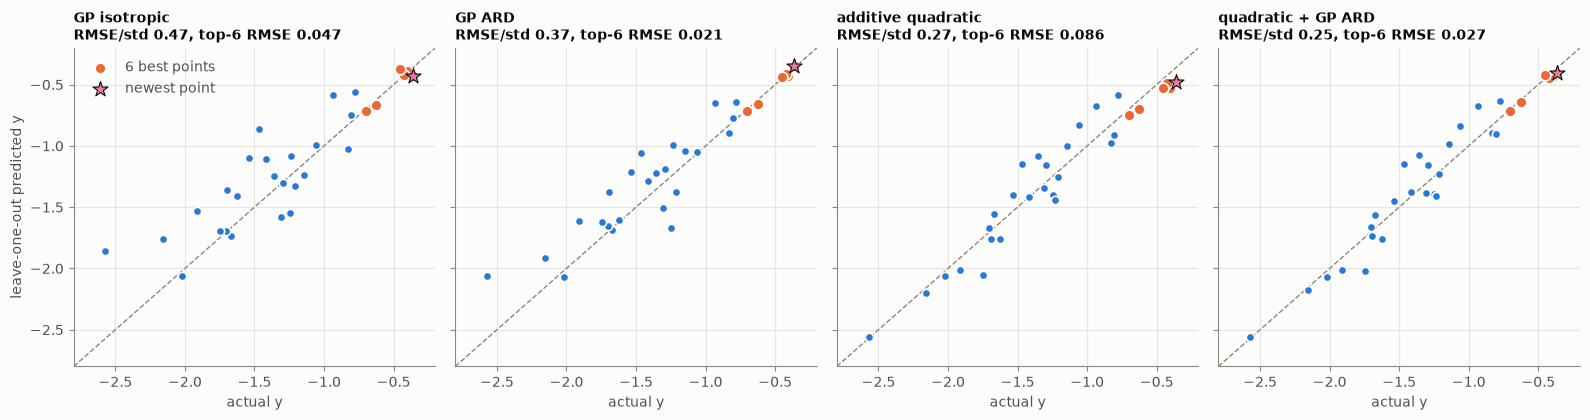

In [4]:
# ---------------------------------------------------------------- 
# Week-11 predictions at the newest point
# ---------------------------------------------------------------- 

models_prev = make_models(X[:NEW], y[:NEW])
prev_pred = {}
print(f"\nWEEK-11 PREDICTIONS at the newest point (models refitted on the first {NEW} rows); observed {y[NEW]:.4f}")
for name, mdl in models_prev.items():
    m, s = mdl.predict(X[NEW])
    prev_pred[name] = (m[0], s[0])
    z = (y[NEW] - m[0]) / s[0] if s[0] > 0 else float("nan")
    print(f"  {name:26s} predicted {m[0]:+.4f} +/- {s[0]:.4f}   error {y[NEW] - m[0]:+.4f}   z = {z:+.2f}")

top = np.argsort(-y)[:6]
loos = {}
print("\nLEAVE-ONE-OUT (hyperparameters fixed at the full fit)")
for name, mdl in models.items():
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        a, b = mdl.refit_fixed().fit(X[keep], y[keep]).predict(X[i:i + 1])
        mu[i], sd[i] = a[0], b[0]
    loos[name] = (mu, sd)
    cover = np.mean(np.abs((y - mu) / np.maximum(sd, 1e-12)) < 1.96) if name != "additive quadratic" else np.nan
    print(f"  {name:26s} RMSE/std={np.sqrt(np.mean((y - mu) ** 2)) / ys:.3f}  Spearman={spearmanr(y, mu)[0]:.3f}  "
          f"top-6 RMSE={np.sqrt(np.mean((y[top] - mu[top]) ** 2)):.3f}  95% coverage={cover:.2f}  "
          f"newest point predicted {mu[NEW]:.3f} (actual {y[NEW]:.3f})")

print('\n')

# Fig 1: LOO predicted vs actual for four models
show = ["GP isotropic", "GP ARD", "additive quadratic", "quadratic + GP ARD"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3), sharey=True)
lim = [-2.8, -0.2]
for ax, name in zip(axes, show):
    mu, sd = loos[name]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.scatter(y, mu, s=36, color=PAL[0], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    ax.scatter(y[top], mu[top], s=60, color=PAL[1], edgecolor=SURFACE, linewidth=1.2, zorder=4, label="6 best points")
    ax.scatter(y[NEW], mu[NEW], s=130, marker="*", color=PAL[4], edgecolor=INK, linewidth=0.8, zorder=5, label="newest point")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("actual y")
    ax.set_title(f"{name}\nRMSE/std {np.sqrt(np.mean((y - mu) ** 2)) / ys:.2f}, top-6 RMSE {np.sqrt(np.mean((y[top] - mu[top]) ** 2)):.3f}", fontsize=10)
axes[0].set_ylabel("leave-one-out predicted y")
axes[0].legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()


CANDIDATES: predicted y by each model; gain = prediction minus the same model's prediction at the best point
  reference: each model at the best observed point: GP isotropic=-0.366  GP ARD=-0.362  additive quadratic=-0.459  quadratic + GP isotropic=-0.364  quadratic + GP ARD=-0.364
  A: EI, ARD GP (full domain)                x = (0.458354, 0.388395, 0.447726, 0.742594, 0.000000)  dist 0.078
      predicted: GP isotropic=-0.363  GP ARD=-0.337  additive quadratic=-0.429  quadratic + GP isotropic=-0.369  quadratic + GP ARD=-0.398
      gain     : GP isotropic=+0.002  GP ARD=+0.026  additive quadratic=+0.029  quadratic + GP isotropic=-0.005  quadratic + GP ARD=-0.034   mean gain +0.0037   models predicting a gain: 3 of 5
      ARD GP sd at the candidate: 0.027
  B: EI, ARD GP (+/-0.1 box)                 x = (0.455808, 0.393143, 0.454006, 0.743748, 0.000000)  dist 0.075
      predicted: GP isotropic=-0.362  GP ARD=-0.336  additive quadratic=-0.426  quadratic + GP isotropic=-0.365  quadra

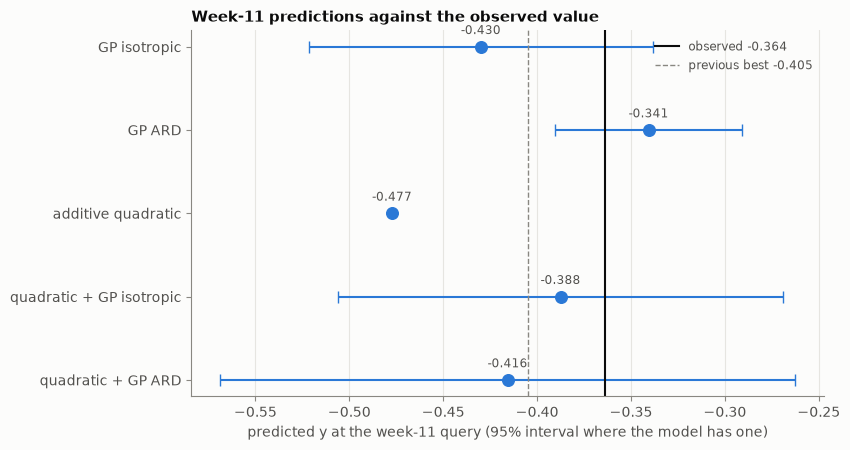

In [5]:
# ---------------------------------------------------------------- 
# Candidates
# ---------------------------------------------------------------- 
gA = models["GP ARD"]
nv = gA.g.kernel_.k2.noise_level
mu_tr, _ = gA.predict(X)
f_inc = (mu_tr.max() - gA.m) / gA.s
S = qmc.Sobol(d, seed=1).random(2 ** 14)

def ei_ard(Z, xi=0.0):
    m, s = gA.g.predict(np.atleast_2d(Z), return_std=True)
    s = np.sqrt(np.maximum(s ** 2 - nv, 1e-18))
    zz = (m - f_inc - xi) / s
    return (m - f_inc - xi) * norm.cdf(zz) + s * norm.pdf(zz)

def box_argmax(fn, r, centre=None):
    c = xb if centre is None else centre
    lo, hi = np.clip(c - r, 0, 1), np.clip(c + r, 0, 1)
    Z = lo + S * (hi - lo)
    v = fn(Z); x0 = Z[v.argmax()]
    res = minimize(lambda q: -fn(q[None])[0], x0, bounds=list(zip(lo, hi)), method="L-BFGS-B")
    return res.x if -res.fun >= v.max() else x0

base = {k: m.predict(xb)[0][0] for k, m in models.items()}
ens_gain = lambda Z: np.mean([m.predict(Z)[0] - base[k] for k, m in models.items()], axis=0)

cq = models["additive quadratic"].c
x_quad = np.clip(-cq[1:d + 1] / (2 * cq[d + 1:]), 0, 1)
x_ei_full = box_argmax(lambda Z: ei_ard(Z, 0.01), 1.0)
x_ei_box = box_argmax(lambda Z: ei_ard(Z, 0.0), 0.1)
x_ens = box_argmax(ens_gain, 0.05)
x_cont = np.clip(xb + 0.5 * (xb - xb_prev), 0, 1)
cands = {
    "A: EI, ARD GP (full domain)": x_ei_full,
    "B: EI, ARD GP (+/-0.1 box)": x_ei_box,
    "C: half-step to A": xb + 0.5 * (x_ei_full - xb),
    "D: continue last step (half)": x_cont,
    "E: quadratic peak": x_quad,
    "F: ensemble-mean max (+/-0.05)": x_ens,
}
pred, gains = {}, {}
print("\nCANDIDATES: predicted y by each model; gain = prediction minus the same model's prediction at the best point")
print(f"  reference: each model at the best observed point: " + "  ".join(f"{k}={v:.3f}" for k, v in base.items()))
for name, xc in cands.items():
    pred[name] = {k: m.predict(xc)[0][0] for k, m in models.items()}
    gains[name] = {k: pred[name][k] - base[k] for k in models}
    print(f"  {name:42s} x = ({', '.join(f'{v:.6f}' for v in xc)})  dist {np.linalg.norm(xc - xb):.3f}")
    print("      predicted: " + "  ".join(f"{k}={v:+.3f}" for k, v in pred[name].items()))
    print("      gain     : " + "  ".join(f"{k}={v:+.3f}" for k, v in gains[name].items())
          + f"   mean gain {np.mean(list(gains[name].values())):+.4f}   models predicting a gain: "
          f"{sum(v > 0 for v in gains[name].values())} of 5")
    sd_a = models['GP ARD'].predict(xc)[1][0]
    print(f"      ARD GP sd at the candidate: {sd_a:.3f}")
print('\n')

# Fig 2: week-11 predictions vs outcome
fig, ax = plt.subplots(figsize=(8.6, 4.6))
names = list(prev_pred)
vals = [prev_pred[k][0] for k in names]
ypos = np.arange(len(names))[::-1]
ax.scatter(vals, ypos, s=70, color=PAL[0], zorder=3)
for k, (v_, p_) in enumerate(zip(vals, ypos)):
    sd_ = prev_pred[names[k]][1]
    if sd_ > 0:
        ax.errorbar([v_], [p_], xerr=[1.96 * sd_], color=PAL[0], capsize=4, lw=1.5, zorder=2)
    ax.annotate(f"{v_:.3f}", (v_, p_), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8.5, color=INK2)
ax.axvline(y[NEW], color=INK, lw=1.5, label=f"observed {y[NEW]:.3f}")
ax.axvline(y[prev_best], color=MUTED, lw=1, ls="--", label=f"previous best {y[prev_best]:.3f}")
ax.set_yticks(ypos); ax.set_yticklabels(names)
ax.set_xlabel("predicted y at the week-11 query (95% interval where the model has one)")
ax.set_title("Week-11 predictions against the observed value")
ax.legend(frameon=False, loc="upper right", fontsize=8.5, labelcolor=INK2)
ax.grid(axis="y", visible=False)
fig.tight_layout()


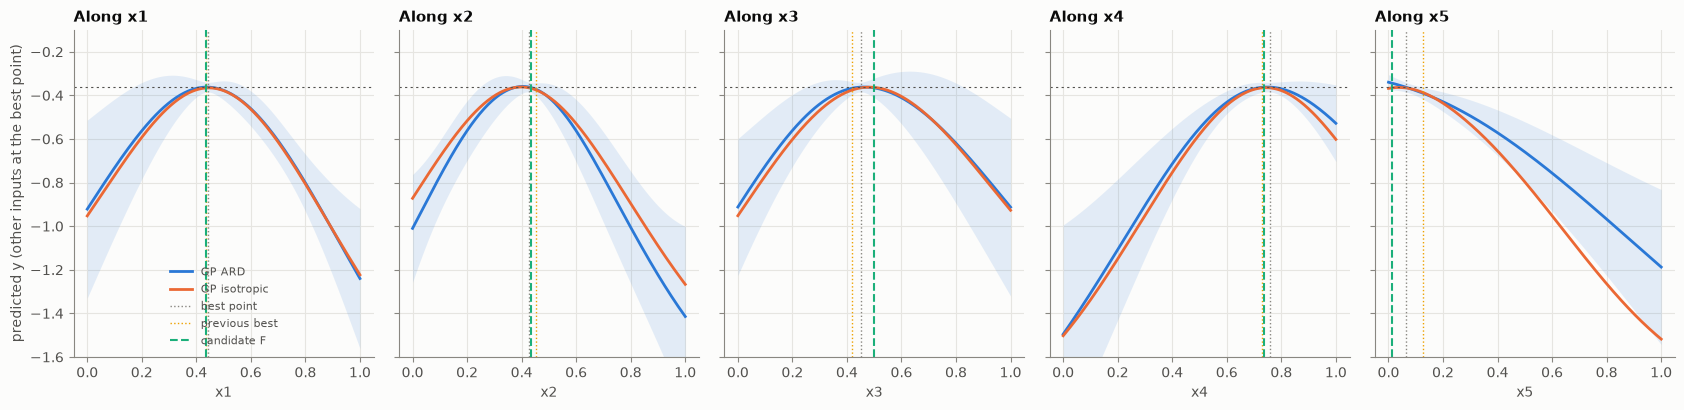

In [6]:
# Fig 3: slices of the ARD and isotropic GPs through the new best point
fig, axes = plt.subplots(1, d, figsize=(17, 4.2), sharey=True)
xs = np.linspace(0, 1, 200)
xRec = cands["F: ensemble-mean max (+/-0.05)"]
for j, ax in enumerate(axes):
    Z = np.tile(xb, (len(xs), 1)); Z[:, j] = xs
    for name, col in [("GP ARD", PAL[0]), ("GP isotropic", PAL[1])]:
        m, s = models[name].predict(Z)
        ax.plot(xs, m, color=col, lw=2, label=name)
        if name == "GP ARD":
            ax.fill_between(xs, m - 2 * s, m + 2 * s, color=col, alpha=0.12, lw=0)
    ax.axvline(xb[j], color=MUTED, lw=1, ls=":", label="best point")
    ax.axvline(xb_prev[j], color=PAL[3], lw=1, ls=":", label="previous best")
    ax.axvline(xRec[j], color=PAL[2], lw=1.5, ls="--", label="candidate F")
    ax.axhline(y.max(), color=INK2, lw=0.8, ls=(0, (2, 3)))
    ax.set_xlabel(f"x{j + 1}"); ax.set_title(f"Along x{j + 1}"); ax.set_ylim(-1.6, -0.1)
axes[0].set_ylabel("predicted y (other inputs at the best point)")
axes[0].legend(frameon=False, loc="lower center", fontsize=8, labelcolor=INK2)
fig.tight_layout()

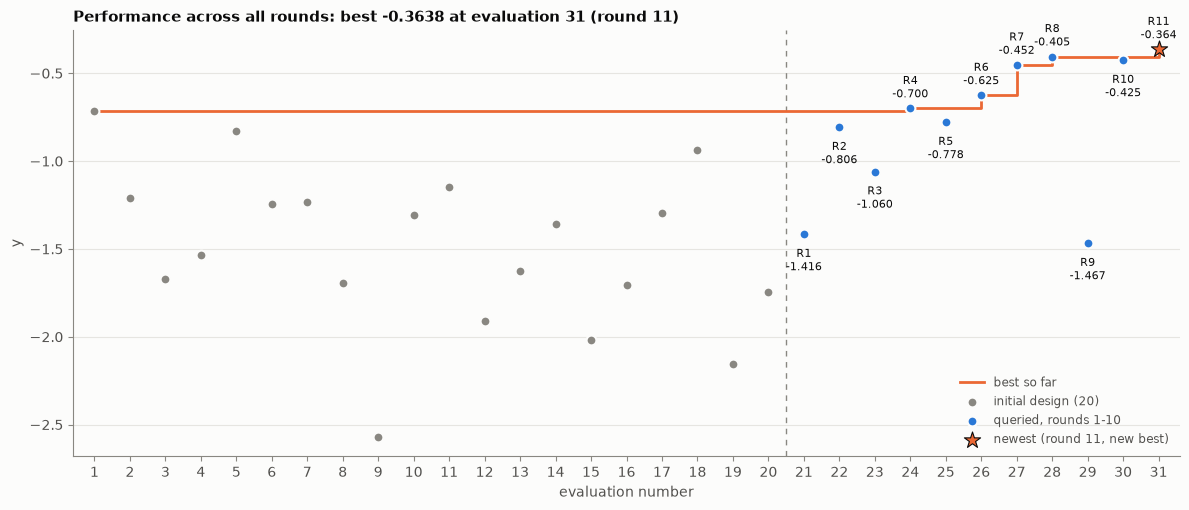

In [7]:
# Fig 4: performance across all rounds
idx = np.arange(1, n + 1)
bsf = np.maximum.accumulate(np.r_[np.full(N_INITIAL, y[:N_INITIAL].max()), y[N_INITIAL:]])
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.axvline(N_INITIAL + 0.5, color=MUTED, lw=1, ls=(0, (4, 4)))
ax.step(idx, bsf, where="post", color=PAL[1], lw=2, label="best so far", zorder=2)
ax.scatter(idx[:N_INITIAL], y[:N_INITIAL], s=50, color=MUTED, edgecolor=SURFACE, linewidth=1.5,
           label=f"initial design ({N_INITIAL})", zorder=3)
ax.scatter(idx[N_INITIAL:NEW], y[N_INITIAL:NEW], s=50, color=PAL[0], edgecolor=SURFACE, linewidth=1.5,
           label=f"queried, rounds 1-{n - N_INITIAL - 1}", zorder=3)
ax.scatter(idx[NEW], y[NEW], s=150, marker="*", color=PAL[1], edgecolor=INK, linewidth=0.8, zorder=4,
           label="newest (round 11, new best)")
for i in range(N_INITIAL, n):
    ax.annotate(f"R{i - N_INITIAL + 1}\n{y[i]:.3f}", (idx[i], y[i]), xytext=(0, 8 if y[i] >= bsf[i] - 1e-12 else -26),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_xticks(idx); ax.set_xlim(0.4, n + 0.6); ax.grid(axis="x", visible=False)
ax.set_xlabel("evaluation number"); ax.set_ylabel("y")
ax.set_title(f"Performance across all rounds: best {y.max():.4f} at evaluation {best + 1} (round {best - N_INITIAL + 1})")
ax.legend(frameon=False, loc="lower right", fontsize=8.5, labelcolor=INK2)
fig.tight_layout()